# Wprowadzenie do uczenia maszynowego - Lista 2
Konrad Słotta 277442

In [39]:
import matplotlib.pyplot as plt
import numpy as np
import os
import pandas as pd
from sklearn.datasets import make_blobs

## Zadanie 1

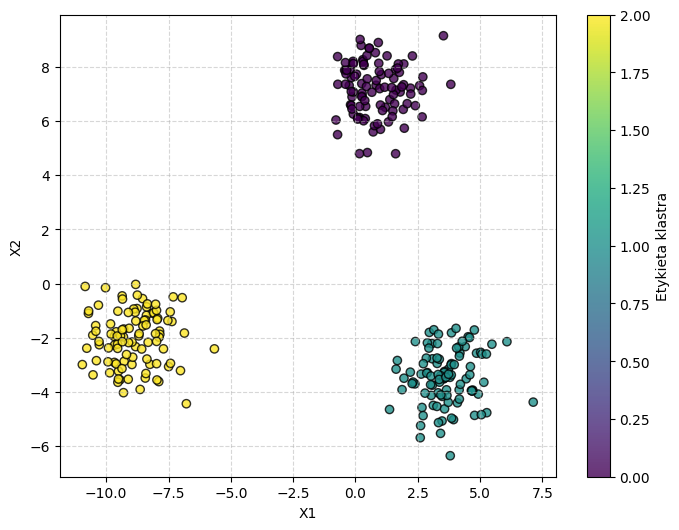

In [30]:
X, y = make_blobs(
    n_samples=300,
    centers=3,
    n_features=2,
    cluster_std=1.0,
    random_state=67
)

plt.figure(figsize=(8, 6))
scatter = plt.scatter(
    X[:, 0], 
    X[:, 1], 
    c=y, 
    edgecolor='k', 
    alpha=0.8
)

plt.xlabel('X1')
plt.ylabel('X2')
plt.colorbar(scatter, label='Etykieta klastra')
plt.grid(True, linestyle='--', alpha=0.5)

plt.show()

## Zadanie 2

In [31]:
class CustomKMeans:
    def __init__(self, k=3, max_iter=100, tol=1e-4, random_state=67):
        self.k = k
        self.max_iter = max_iter
        self.tol = tol
        self.random_state = random_state
        self.centroids = None
        self.labels = None

    def fit(self, X):
        np.random.seed(self.random_state)
        n_samples, n_features = X.shape

        random_indices = np.random.choice(n_samples, self.k, replace=False)
        self.centroids = X[random_indices].copy()

        for iteration in range(self.max_iter):
            distances = np.linalg.norm(X[:, np.newaxis] - self.centroids, axis=2)
            self.labels = np.argmin(distances, axis=1)

            new_centroids = np.zeros_like(self.centroids)
            for j in range(self.k):
                cluster_points = X[self.labels == j]
                if len(cluster_points) > 0:
                    new_centroids[j] = cluster_points.mean(axis=0)
                else:
                    new_centroids[j] = self.centroids[j]

            centroid_shift = np.linalg.norm(new_centroids - self.centroids)
            self.centroids = new_centroids

            if centroid_shift < self.tol:
                print(f"Zbieżność osiągnięta w iteracji {iteration + 1}")
                break

        return self

    def predict(self, X):
        distances = np.linalg.norm(X[:, np.newaxis] - self.centroids, axis=2)
        return np.argmin(distances, axis=1)

Zbieżność osiągnięta w iteracji 3


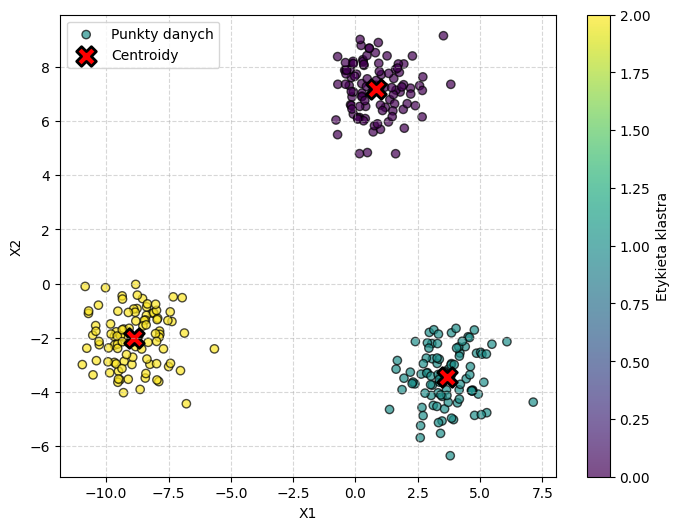

In [32]:
kmeans = CustomKMeans(k=3, random_state=67)
kmeans.fit(X)

plt.figure(figsize=(8, 6))

scatter = plt.scatter(
    X[:, 0], 
    X[:, 1], 
    c=kmeans.labels, 
    cmap='viridis', 
    alpha=0.7, 
    edgecolor='k',
    label='Punkty danych'
)

plt.scatter(
    kmeans.centroids[:, 0], 
    kmeans.centroids[:, 1], 
    c='red', 
    marker='X', 
    s=200, 
    linewidths=2, 
    edgecolor='black', 
    label='Centroidy'
)

plt.xlabel('X1')
plt.ylabel('X2')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.colorbar(scatter, label='Etykieta klastra')

plt.show()

## Zadanie 3

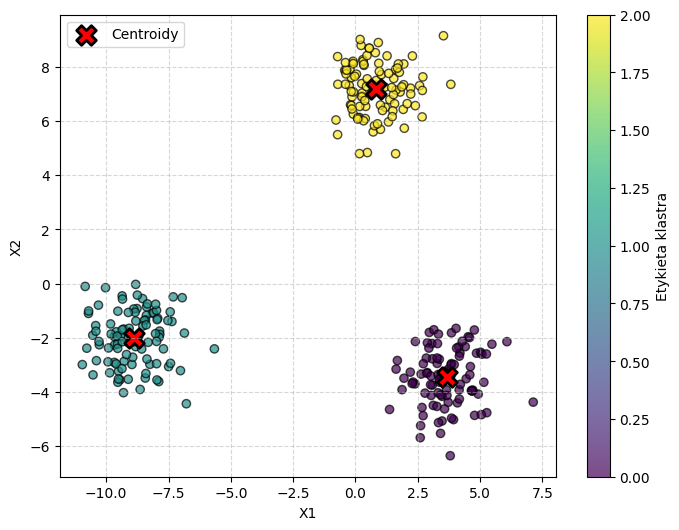

In [33]:
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=3, random_state=67, n_init=10)
labels = kmeans.fit_predict(X)
centroids = kmeans.cluster_centers_

plt.figure(figsize=(8, 6))

scatter = plt.scatter(
    X[:, 0], 
    X[:, 1], 
    c=labels, 
    cmap='viridis', 
    alpha=0.7, 
    edgecolor='k'
)

plt.scatter(
    centroids[:, 0], 
    centroids[:, 1], 
    c='red', 
    marker='X', 
    s=200, 
    linewidths=2, 
    edgecolor='black', 
    label='Centroidy'
)

plt.xlabel('X1')
plt.ylabel('X2')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.colorbar(scatter, label='Etykieta klastra')

plt.show()

## Zadanie 4

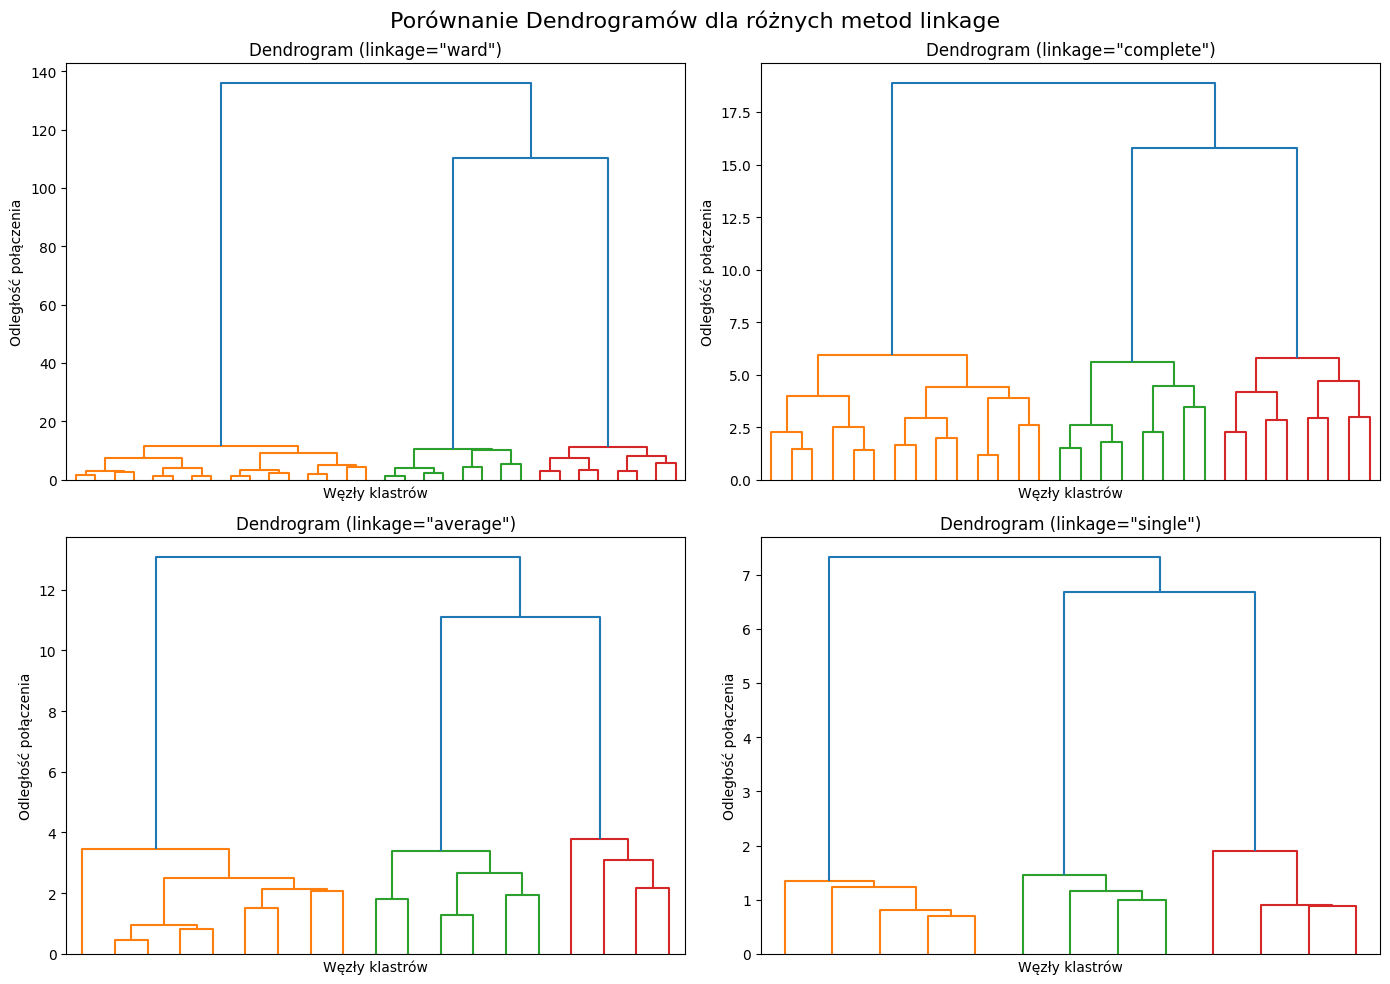

In [34]:
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage

linkage_methods = ['ward', 'complete', 'average', 'single']

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.ravel()

for i, method in enumerate(linkage_methods):
    Z = linkage(X, method=method)
    
    dendrogram(Z, ax=axes[i], truncate_mode='level', p=4, no_labels=True)
    axes[i].set_title(f'Dendrogram (linkage="{method}")')
    axes[i].set_xlabel('Węzły klastrów')
    axes[i].set_ylabel('Odległość połączenia')

plt.suptitle('Porównanie Dendrogramów dla różnych metod linkage', fontsize=16)
plt.tight_layout()
plt.show()

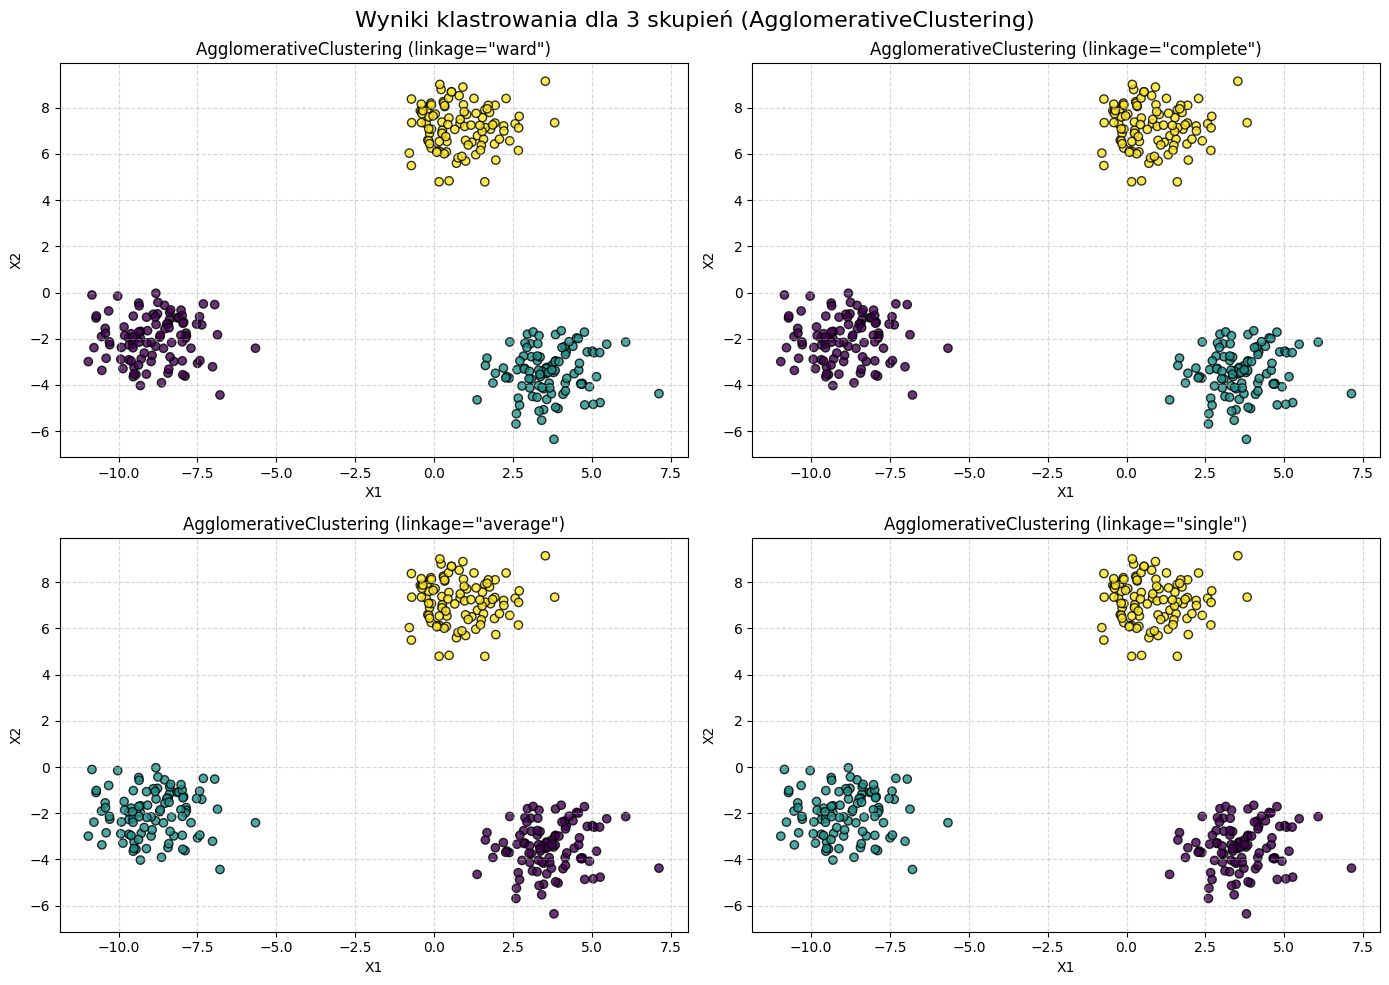

In [35]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.ravel()

for i, method in enumerate(linkage_methods):
    model = AgglomerativeClustering(n_clusters=3, linkage=method)
    labels = model.fit_predict(X)
    
    axes[i].scatter(X[:, 0], X[:, 1], c=labels, cmap='viridis', alpha=0.8, edgecolor='k')
    axes[i].set_title(f'AgglomerativeClustering (linkage="{method}")')
    axes[i].set_xlabel('X1')
    axes[i].set_ylabel('X2')
    axes[i].grid(True, linestyle='--', alpha=0.5)

plt.suptitle('Wyniki klastrowania dla 3 skupień (AgglomerativeClustering)', fontsize=16)
plt.tight_layout()
plt.show()

## Zadanie 5

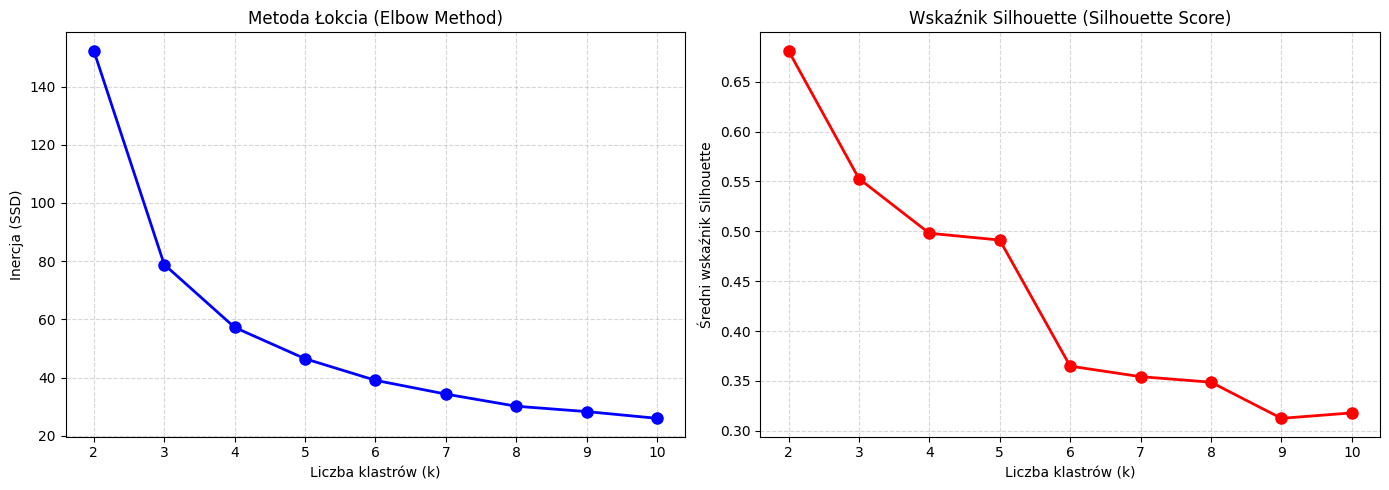

In [36]:
from sklearn.datasets import load_iris
from sklearn.metrics import silhouette_score

iris = load_iris()
X_iris = iris.data

k_range = range(2, 11)
inertia_list = []
silhouette_list = []

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_iris)
    
    inertia_list.append(kmeans.inertia_)
    silhouette_list.append(silhouette_score(X_iris, labels))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(k_range, inertia_list, 'bo-', linewidth=2, markersize=8)
axes[0].set_title('Metoda Łokcia (Elbow Method)')
axes[0].set_xlabel('Liczba klastrów (k)')
axes[0].set_ylabel('Inercja (SSD)')
axes[0].grid(True, linestyle='--', alpha=0.5)
axes[0].set_xticks(k_range)

axes[1].plot(k_range, silhouette_list, 'ro-', linewidth=2, markersize=8)
axes[1].set_title('Wskaźnik Silhouette (Silhouette Score)')
axes[1].set_xlabel('Liczba klastrów (k)')
axes[1].set_ylabel('Średni wskaźnik Silhouette')
axes[1].grid(True, linestyle='--', alpha=0.5)
axes[1].set_xticks(k_range)

plt.tight_layout()
plt.show()

## Zadanie 6

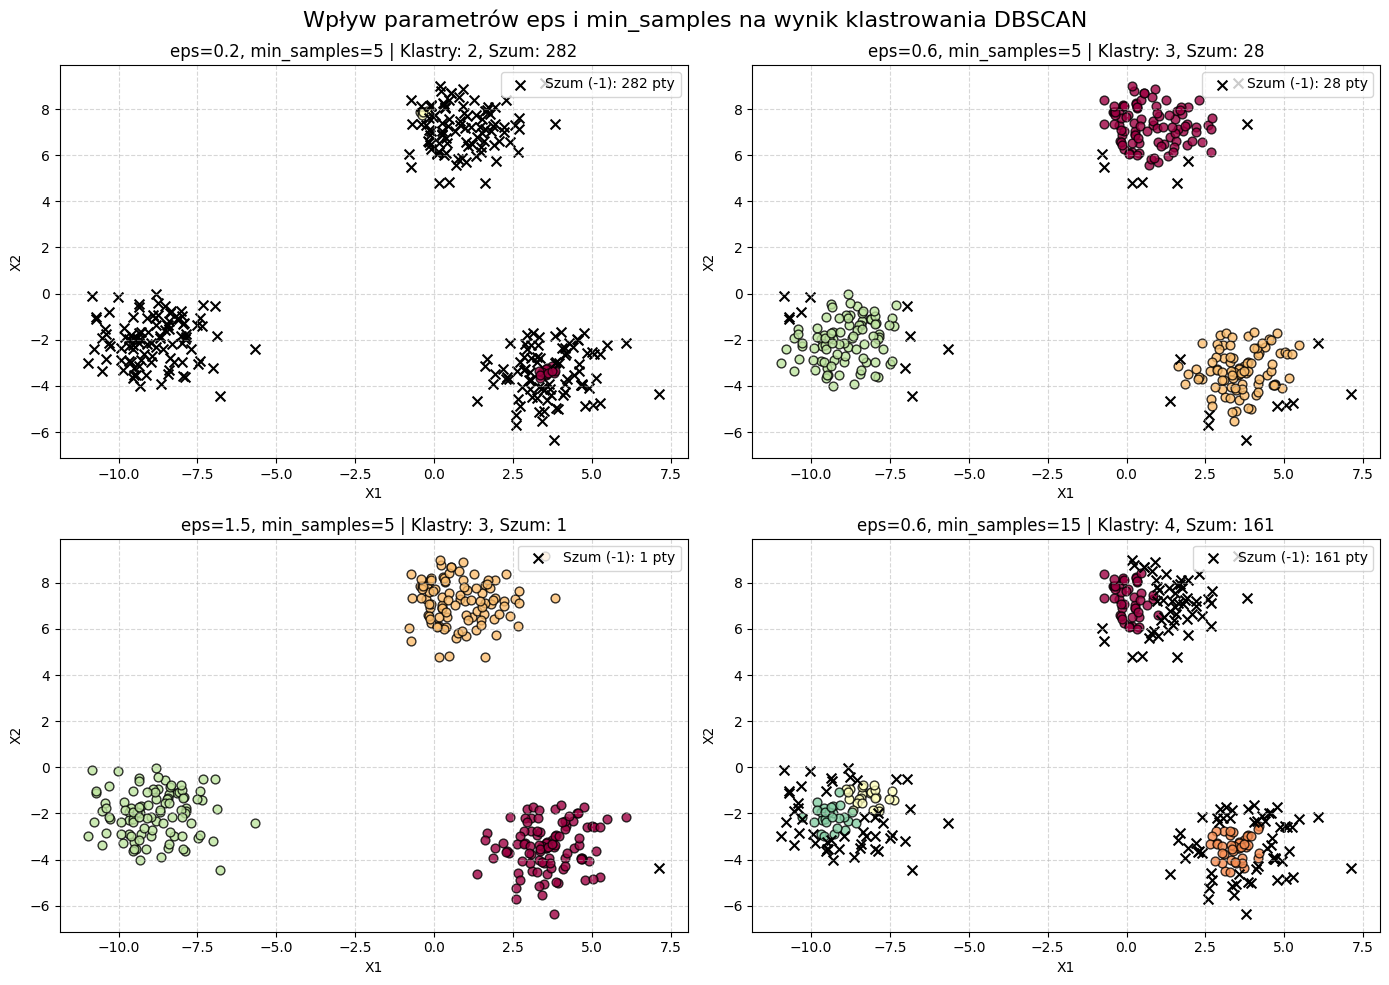

In [37]:
from sklearn.cluster import DBSCAN

param_grid = [
    {'eps': 0.2, 'min_samples': 5},
    {'eps': 0.6, 'min_samples': 5},
    {'eps': 1.5, 'min_samples': 5},
    {'eps': 0.6, 'min_samples': 15}
]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.ravel()

for i, params in enumerate(param_grid):
    eps = params['eps']
    min_samples = params['min_samples']
    
    dbscan = DBSCAN(eps=eps, min_samples=min_samples)
    labels = dbscan.fit_predict(X)
    
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    n_noise = np.sum(labels == -1)
    
    unique_labels = set(labels)
    colors = [plt.cm.Spectral(each) for each in np.linspace(0, 1, len(unique_labels))]
    
    for k, col in zip(unique_labels, colors):
        class_member_mask = (labels == k)
        xy = X[class_member_mask]
        
        if k == -1:
            axes[i].scatter(
                xy[:, 0], xy[:, 1], 
                c='black', marker='x', s=50, 
                label=f'Szum (-1): {n_noise} pty'
            )
        else:
            axes[i].scatter(
                xy[:, 0], xy[:, 1], 
                c=[col], marker='o', s=40, alpha=0.8, edgecolor='k'
            )
            
    axes[i].set_title(f'eps={eps}, min_samples={min_samples} | Klastry: {n_clusters}, Szum: {n_noise}')
    axes[i].set_xlabel('X1')
    axes[i].set_ylabel('X2')
    axes[i].grid(True, linestyle='--', alpha=0.5)
    axes[i].legend(loc='upper right')

plt.suptitle('Wpływ parametrów eps i min_samples na wynik klastrowania DBSCAN', fontsize=16)
plt.tight_layout()
plt.show()

## Zadanie 7

   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40


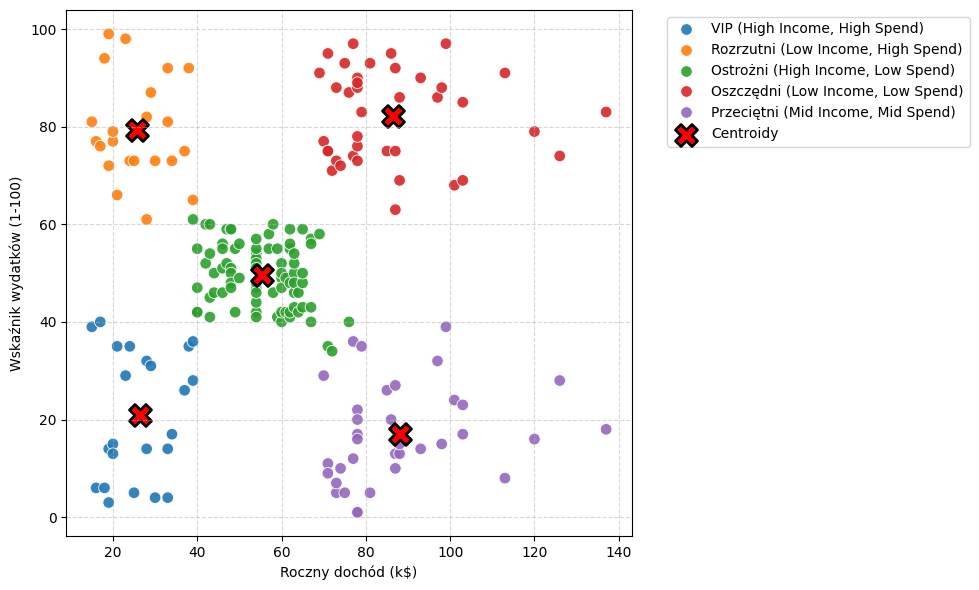

In [44]:
import seaborn as sns
import kagglehub

path = kagglehub.dataset_download("vjchoudhary7/customer-segmentation-tutorial-in-python")

csv_file = os.path.join(path, "Mall_Customers.csv")
df = pd.read_csv(csv_file)

print(df.head())

X = df[['Annual Income (k$)', 'Spending Score (1-100)']].values

kmeans = KMeans(n_clusters=5, random_state=67, n_init=10)
df['Cluster'] = kmeans.fit_predict(X)
centroids = kmeans.cluster_centers_

cluster_names = {
    0: 'Ostrożni (High Income, Low Spend)',
    1: 'Przeciętni (Mid Income, Mid Spend)',
    2: 'VIP (High Income, High Spend)',
    3: 'Oszczędni (Low Income, Low Spend)',
    4: 'Rozrzutni (Low Income, High Spend)'
}
df['Segment'] = df['Cluster'].map(cluster_names)

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df, 
    x='Annual Income (k$)', 
    y='Spending Score (1-100)', 
    hue='Segment', 
    palette='tab10', 
    s=70, 
    alpha=0.9
)

plt.scatter(
    centroids[:, 0], 
    centroids[:, 1], 
    c='red', 
    marker='X', 
    s=250, 
    linewidths=2, 
    edgecolor='black', 
    label='Centroidy'
)

plt.xlabel('Roczny dochód (k$)')
plt.ylabel('Wskaźnik wydatków (1-100)')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()